In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install dataprep

     |████████████████████████████████| 193 kB 894 kB/s 
     |████████████████████████████████| 848 kB 4.5 MB/s 
     |████████████████████████████████| 1.4 MB 5.8 MB/s 
     |████████████████████████████████| 428 kB 7.2 MB/s 
     |████████████████████████████████| 49 kB 2.5 MB/s 
  Created wheel for nltk: filename=nltk-3.5-py3-none-any.whl size=1434675 sha256=8e79a2dcb504cffdf656e711ce0c81401b6a57eaaff6bf87ae4afd1530edb01d
  Stored in directory: /root/.cache/pip/wheels/45/6c/46/a1865e7ba706b3817f5d1b2ff7ce8996aabdd0d03d47ba0266
Successfully built nltk
  Attempting uninstall: tornado
    Found existing installation: tornado 5.0.2
    Uninstalling tornado-5.0.2:
      Successfully uninstalled tornado-5.0.2
  Attempting uninstall: dask
    Found existing installation: dask 2021.2.0
    Uninstalling dask-2021.2.0:
      Successfully uninstalled dask-2021.2.0
  Attempting uninstall: nltk
    Found existing installation: nltk 3.2.4
    Uninstalling nltk-3.2.4:
      Successfully uninstall

In [3]:
from dataprep.eda import *


In [4]:
df = pd.read_csv('../input/credit-card-customers/BankChurners.csv')

In [5]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [6]:
df = df.drop(["CLIENTNUM", 
              "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1", 
              "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2"
             ], axis=1)
df.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [7]:
# Finding all the categorical columns from the data
df.select_dtypes(exclude=['int64','float64']).columns


Index(['Attrition_Flag', 'Gender', 'Education_Level', 'Marital_Status',
       'Income_Category', 'Card_Category'],
      dtype='object')

/opt/conda/lib/python3.7/site-packages/dask/dataframe/accessor.py:48: FutureWarning: The default value of regex will change from True to False in a future version.
  out = getattr(getattr(obj, accessor, obj), attr)(*args, **kwargs)
/opt/conda/lib/python3.7/site-packages/dask/dataframe/accessor.py:48: FutureWarning: The default value of regex will change from True to False in a future version.
  out = getattr(getattr(obj, accessor, obj), attr)(*args, **kwargs)
/opt/conda/lib/python3.7/site-packages/dask/dataframe/accessor.py:48: FutureWarning: The default value of regex will change from True to False in a future version.
  out = getattr(getattr(obj, accessor, obj), attr)(*args, **kwargs)
/opt/conda/lib/python3.7/site-packages/dask/dataframe/accessor.py:48: FutureWarning: The default value of regex will change from True to False in a future version.
  out = getattr(getattr(obj, accessor, obj), attr)(*args, **kwargs)
/opt/conda/lib/python3.7/site-packages/dask/dataframe/accessor.py:48: Fu

  0%|          | 0/2624 [00:00<?, ?it/s]

/opt/conda/lib/python3.7/site-packages/dask/dataframe/accessor.py:48: FutureWarning: The default value of regex will change from True to False in a future version.
  out = getattr(getattr(obj, accessor, obj), attr)(*args, **kwargs)


DataPrep Report
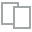
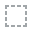
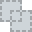
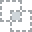
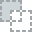
...
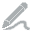
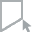
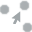
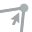
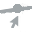

In [8]:
create_report(df)

In [9]:
df.Attrition_Flag.replace({'Existing Customer': 1, 'Attrited Customer': 0}, inplace=True)

df.Gender.replace({'F': 0, 'M': 1}, inplace=True)

df.Education_Level.replace({'Graduate': 0, 'High School': 1, 'Unknown': 2,'Uneducated':3,'College':4,'Post-Graduate':5,'Doctorate':6}, inplace=True)

df.Marital_Status.replace({'Married': 0, 'Single': 1,'Unknown':2,'Divorced':3}, inplace=True)

df.Income_Category.replace({'Less than $40K': 0,'$80K - $120K': 1, '$60K - $80K': 2,'Unknown':3}, inplace=True)

df.Card_Category.replace({'Blue': 0, 'Silver': 1,'Gold':2,'Platinum':3}, inplace=True)

df.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,1,45,1,3,1,0,2,0,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,1,49,0,5,0,1,0,0,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,1,51,1,3,0,0,1,0,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,1,40,0,4,1,2,0,0,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,1,40,1,3,3,0,2,0,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


  0%|          | 0/10 [00:00<?, ?it/s]


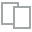
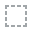
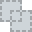
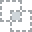
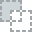
...
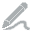
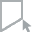
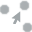
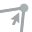
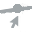

In [10]:
plot(df, "Customer_Age", "Attrition_Flag")


  0%|          | 0/10 [00:00<?, ?it/s]


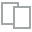
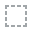
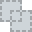
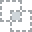
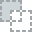
...
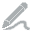
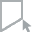
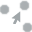
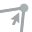
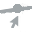

In [11]:
plot(df, "Dependent_count", "Attrition_Flag")


  0%|          | 0/10 [00:00<?, ?it/s]


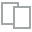
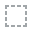
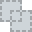
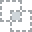
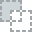
...
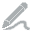
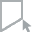
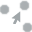
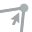
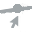

In [12]:
plot(df, "Education_Level", "Attrition_Flag")


  0%|          | 0/10 [00:00<?, ?it/s]


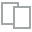
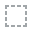
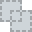
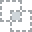
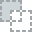
...
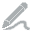
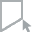
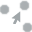
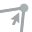
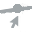

In [13]:
plot(df, "Marital_Status", "Attrition_Flag")


  0%|          | 0/30 [00:00<?, ?it/s]


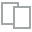
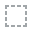
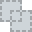
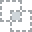
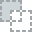
...
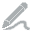
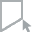
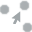
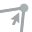
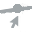

In [14]:
plot(df, "Income_Category", "Attrition_Flag")


  0%|          | 0/10 [00:00<?, ?it/s]


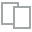
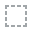
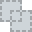
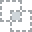
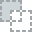
...
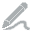
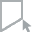
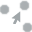
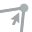
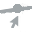

In [15]:
plot(df, "Card_Category", "Attrition_Flag")


  0%|          | 0/10 [00:00<?, ?it/s]


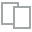
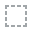
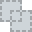
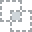
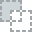
...
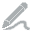
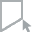
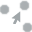
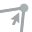
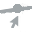

In [16]:
plot(df, "Months_on_book", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


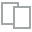
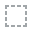
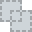
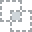
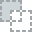
...
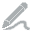
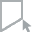
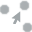
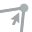
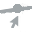

In [17]:
plot(df, "Months_on_book", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


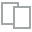
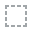
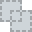
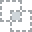
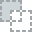
...
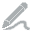
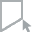
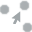
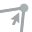
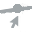

In [18]:
plot(df, "Credit_Limit", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


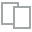
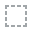
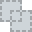
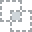
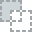
...
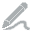
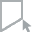
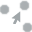
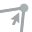
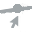

In [19]:

plot(df, "Total_Revolving_Bal", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


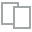
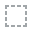
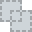
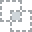
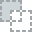
...
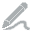
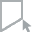
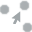
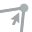
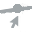

In [20]:
plot(df, "Avg_Open_To_Buy", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


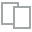
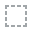
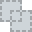
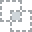
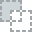
...
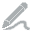
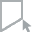
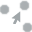
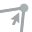
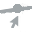

In [21]:
plot(df, "Total_Amt_Chng_Q4_Q1", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


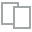
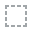
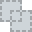
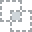
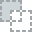
...
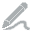
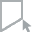
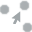
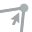
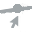

In [22]:
plot(df, "Total_Trans_Amt", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


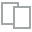
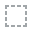
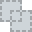
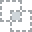
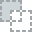
...
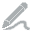
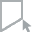
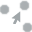
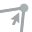
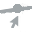

In [23]:
plot(df, "Total_Trans_Ct", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


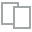
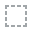
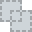
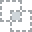
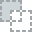
...
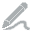
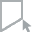
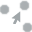
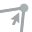
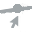

In [24]:
plot(df, "Total_Ct_Chng_Q4_Q1", "Attrition_Flag")

  0%|          | 0/10 [00:00<?, ?it/s]


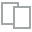
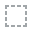
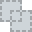
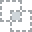
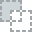
...
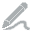
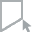
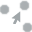
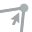
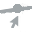

In [25]:
plot(df, "Avg_Utilization_Ratio", "Attrition_Flag")

  0%|          | 0/433 [00:00<?, ?it/s]


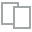
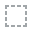
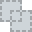
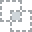
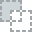
...
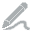
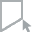
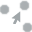
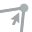
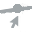

In [26]:
plot_correlation(df, "Attrition_Flag")


In [27]:
df = df.drop(["Gender", "Credit_Limit", "Avg_Open_To_Buy",
              'Months_on_book','Marital_Status','Customer_Age',
              'Dependent_count','Education_Level','Income_Category'
             ], axis=1)


In [28]:
X = df.drop(columns=["Attrition_Flag"])
y = df["Attrition_Flag"]

In [29]:
from sklearn.model_selection import train_test_split

#Splitting data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=44, shuffle =True)


In [30]:
from sklearn.ensemble import GradientBoostingClassifier

#Applying GradientBoostingClassifier Model 


GBCModel = GradientBoostingClassifier(n_estimators=100,max_depth=3,random_state=33) 
GBCModel.fit(X_train, y_train)

#Calculating Details
print('GBCModel Train Score is : ' , GBCModel.score(X_train, y_train))
print('GBCModel Test Score is : ' , GBCModel.score(X_test, y_test))
#print('----------------------------------------------------')

#Calculating Prediction
y_pred = GBCModel.predict(X_test)
y_pred_prob = GBCModel.predict_proba(X_test)
#print('Predicted Value for GBCModel is : ' , y_pred[:10])
#print('Prediction Probabilities Value for GBCModel is : ' , y_pred_prob[:10])

GBCModel Train Score is :  0.9708179808400884
GBCModel Test Score is :  0.964691801316577


Confusion Matrix is : 
 [[ 450   85]
 [  33 2774]]


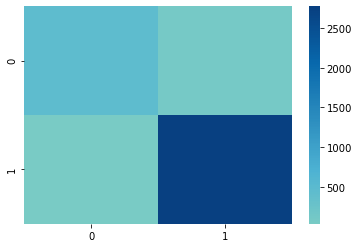

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

#Calculating Confusion Matrix
CM = confusion_matrix(y_test, y_pred)
print('Confusion Matrix is : \n', CM)

# drawing confusion matrix
sns.heatmap(CM, center = True,cmap='GnBu')
plt.show()